# Cross-flicker count — Passive cohort

Participants were asked to count how many times the screen flickered
during the two oddball blocks. This measures passive attention to the
auditory oddball task.

Analyses:
1. Oddball 1 vs Oddball 2 block comparison (paired t-test + violin)
2. VG status (proxy via action score median split) vs counting accuracy

Source: `3_data_summary_passive.csv` (manual entry from experiment log).
No separate preprocessing step needed.

Last edit: 16.10.2026 @anguyen

In [11]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import seaborn as sns
from pathlib import Path
from datetime import datetime

def find_repo_root(marker='core') -> Path:
    for candidate in [Path.cwd(), *Path.cwd().parents]:
        if (candidate / marker).is_dir():
            return candidate
    raise RuntimeError(f"Could not locate repo root (no '{marker}/' found above {Path.cwd()})")

sys.path.insert(0, str(find_repo_root() / 'core'))
from participants import get_participants

DATE_STR = datetime.today().strftime('%Y%m%d')

if sys.platform == 'win32':
    root         = Path('L:/EEG_Flow_data/Study_EEG_Flow_Passive/derivatives_v2')
    source_dir   = Path('L:/EEG_Flow_data/Study_EEG_Flow_Passive/raw/participant_records/experiment_log')
    root_img     = Path('L:/EEG_Flow_data/Study_EEG_Flow_Passive/derivatives_v2/outputs/img/behavior')
    measures_dir = Path('L:/EEG_Flow_data/Study_EEG_Flow_Passive/derivatives_v2/outputs/measures/behavior')
else:
    root         = Path('/Volumes/faculty/EEG_Flow_data/Study_EEG_Flow_Passive/derivatives_v2')
    source_dir   = Path('/Volumes/faculty/EEG_Flow_data/Study_EEG_Flow_Passive/raw/participant_records/experiment_log')
    root_img     = Path('/Volumes/faculty/EEG_Flow_data/Study_EEG_Flow_Passive/derivatives_v2/outputs/img/behavior')
    measures_dir = Path('/Volumes/faculty/EEG_Flow_data/Study_EEG_Flow_Passive/derivatives_v2/outputs/measures/behavior')

root_img.mkdir(parents=True, exist_ok=True)
measures_dir.mkdir(parents=True, exist_ok=True)

DATE_ACTION = '20261016'  # date of action_score CSV

# correct counts per block (ground truth)
CONDITIONS = ['Oddball 1', 'Oddball 2']
CORRECT    = {'Oddball 1': 15, 'Oddball 2': 19}

In [12]:
# ==============================================================================
# Load and filter data
# ==============================================================================

included_passive = list(get_participants('load', 'passive').keys())
print(f'N included: {len(included_passive)}')

df = pd.read_excel(source_dir / '3_Data_summary_passive.xlsx',
    header=1
)
df['count2_clean'] = pd.to_numeric(df['count2'], errors='coerce')
df['count3_clean'] = pd.to_numeric(df['count3'], errors='coerce')

df_filtered = df[df['Participant ID'].isin(included_passive)].copy()
print(f'count2 NaN: {df_filtered["count2_clean"].isna().sum()}')
print(f'count3 NaN: {df_filtered["count3_clean"].isna().sum()}')

# reshape to long format
df_plot = pd.melt(
    df_filtered[['Participant ID', 'count2_clean', 'count3_clean']],
    id_vars='Participant ID',
    value_vars=['count2_clean', 'count3_clean'],
    var_name='block', value_name='count'
).dropna()
df_plot['block']   = df_plot['block'].map({'count2_clean': 'Oddball 1', 'count3_clean': 'Oddball 2'})
df_plot['correct'] = df_plot['block'].map(CORRECT)
df_plot['pct_error'] = (df_plot['count'] - df_plot['correct']) / df_plot['correct'] * 100
print(f'\nLong format: {len(df_plot)} rows')

N included: 47
count2 NaN: 1
count3 NaN: 2

Long format: 91 rows


Paired t-test Oddball 1 vs Oddball 2: t=-1.085, p=0.2842
-> Pooling justified.
Saved -> 20261016_passive_cross_flicker_block_comparison.svg


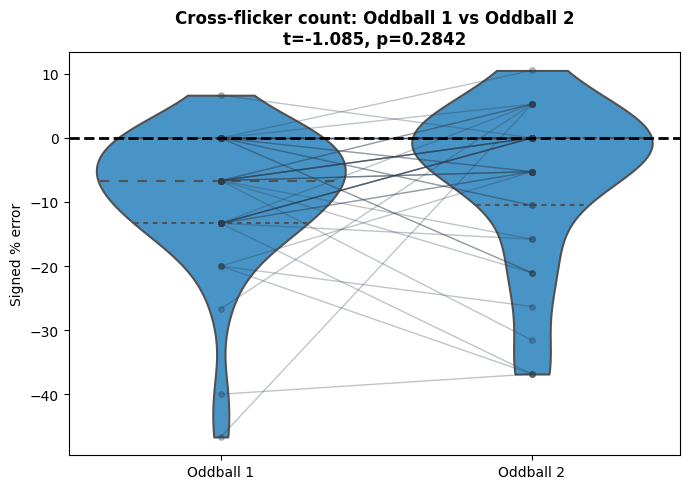

In [16]:
# ==============================================================================
# Step 1: Oddball 1 vs Oddball 2 — confirm poolable
# ==============================================================================

paired = df_plot.pivot(index='Participant ID', columns='block', values='pct_error').dropna()
t_block, p_block = stats.ttest_rel(paired['Oddball 1'], paired['Oddball 2'])
print(f'Paired t-test Oddball 1 vs Oddball 2: t={t_block:.3f}, p={p_block:.4f}')
print('-> Pooling justified.' if p_block >= 0.05 else '-> WARNING: significant block difference.')

fig, ax = plt.subplots(figsize=(7, 5))
sns.violinplot(data=df_plot, x='block', y='pct_error',
               color='#3498DB', order=CONDITIONS,
               cut=0, inner='quart', ax=ax)

for pid in df_plot['Participant ID'].unique():
    pdata = df_plot[df_plot['Participant ID'] == pid].set_index('block')
    if set(CONDITIONS).issubset(pdata.index):
        ax.plot([0, 1], [pdata.loc['Oddball 1', 'pct_error'],
                         pdata.loc['Oddball 2', 'pct_error']],
                marker='o', linestyle='-', color='#2C3E50', alpha=0.3,
                linewidth=1, markersize=4)

ax.axhline(0, color='black', linewidth=2, linestyle='--')
ax.set_ylabel('Signed % error')
ax.set_xlabel(None)
ax.set_title(f'Cross-flicker count: Oddball 1 vs Oddball 2\nt={t_block:.3f}, p={p_block:.4f}',
             fontweight='bold')
plt.tight_layout()
fname = root_img / f'{DATE_STR}_passive_cross_flicker_block_comparison.svg'
plt.savefig(fname, dpi=300, bbox_inches='tight')
print(f'Saved -> {fname.name}')
plt.show()

## Introducing VG

In [13]:
# ==============================================================================
# VG status proxy via action score median split
# ==============================================================================

fname_action = measures_dir / f'{DATE_ACTION}_passive_action_score.csv'
df_action    = pd.read_csv(fname_action)
df_action    = df_action[df_action['participant'].isin(included_passive)]
print(f'Action score: {len(df_action)} participants')

action_col    = 'action_past_hours'
MANUAL_CUTOFF = None  # set to a number to override median split

cutoff       = MANUAL_CUTOFF if MANUAL_CUTOFF is not None else df_action[action_col].median()
cutoff_label = f'manual={cutoff}' if MANUAL_CUTOFF else f'median={cutoff:.2f}'

df_action['VG_status'] = np.where(df_action[action_col] >= cutoff, 'VG', 'NVG')
print(f'Using {cutoff_label}')
print(df_action['VG_status'].value_counts())

vg_map   = df_action.set_index('participant')['VG_status']
df_plot['VG_status'] = df_plot['Participant ID'].map(vg_map)

Action score: 47 participants
Using median=12.50
VG_status
VG     24
NVG    23
Name: count, dtype: int64


In [17]:
# ==============================================================================
# Step 2: Build pooled df (mean % error per participant across blocks)
# ==============================================================================

df_pooled = (
    df_plot.dropna(subset=['VG_status'])
    .groupby(['Participant ID', 'VG_status'], as_index=False)['pct_error']
    .mean()
)
print(f'N pooled: {len(df_pooled)}')
print(df_pooled['VG_status'].value_counts())

# sanity — participants contributing only 1 block
counts_per_pid = df_plot.dropna(subset=['VG_status']).groupby('Participant ID').size()
incomplete = counts_per_pid[counts_per_pid < 2]
if len(incomplete):
    print(f'\nParticipants with only 1 block: {list(incomplete.index)}')

N pooled: 47
VG_status
VG     24
NVG    23
Name: count, dtype: int64

Participants with only 1 block: ['S08', 'S13', 'S39']


VG status t-test (median=12.50): t=-1.644, p=0.1072
Saved -> 20261016_passive_cross_flicker_VGstatus.svg


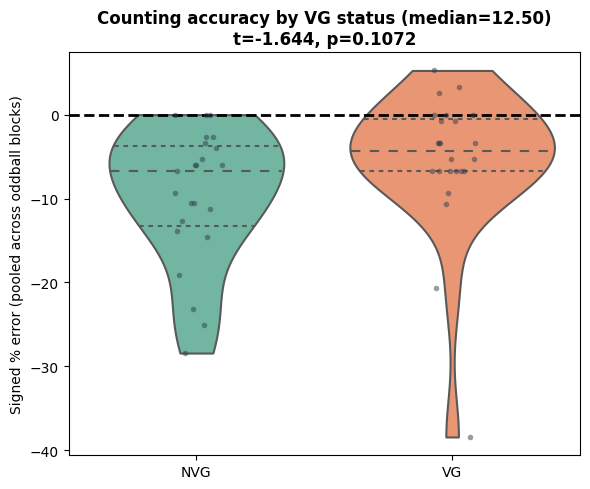

In [20]:
# ==============================================================================
# Step 3: VG status vs counting accuracy
# ==============================================================================

groups = df_pooled['VG_status'].unique()
t_vg, p_vg = stats.ttest_ind(
    df_pooled.loc[df_pooled['VG_status'] == groups[0], 'pct_error'],
    df_pooled.loc[df_pooled['VG_status'] == groups[1], 'pct_error'],
)
print(f'VG status t-test ({cutoff_label}): t={t_vg:.3f}, p={p_vg:.4f}')

fig, ax = plt.subplots(figsize=(6, 5))
sns.violinplot(data=df_pooled, x='VG_status', y='pct_error',
               cut=0, inner='quart', ax=ax, palette='Set2')
sns.stripplot(data=df_pooled, x='VG_status', y='pct_error',
              color='#2C3E50', alpha=0.5, size=4, ax=ax)
ax.axhline(0, color='black', linewidth=2, linestyle='--')
ax.set_ylabel('Signed % error (pooled across oddball blocks)')
ax.set_xlabel(None)
ax.set_title(f'Counting accuracy by VG status ({cutoff_label})\nt={t_vg:.3f}, p={p_vg:.4f}',
             fontweight='bold')
plt.tight_layout()
fname = root_img / f'{DATE_STR}_passive_cross_flicker_VGstatus.svg'
plt.savefig(fname, dpi=300, bbox_inches='tight')
print(f'Saved -> {fname.name}')
plt.show()

In [19]:
# ==============================================================================
# Robustness check: with vs without single-block participants
# ==============================================================================

incomplete_ids = list(incomplete.index) if len(incomplete) else []

if incomplete_ids:
    df_pooled_excl = df_pooled[~df_pooled['Participant ID'].isin(incomplete_ids)]
    t_excl, p_excl = stats.ttest_ind(
        df_pooled_excl.loc[df_pooled_excl['VG_status'] == groups[0], 'pct_error'],
        df_pooled_excl.loc[df_pooled_excl['VG_status'] == groups[1], 'pct_error'],
    )
    print(f'Excl. single-block ({incomplete_ids}): t={t_excl:.3f}, p={p_excl:.4f}')
    print(f'Full sample:                          t={t_vg:.3f},   p={p_vg:.4f}')
else:
    print('All participants contributed 2 blocks — no robustness check needed.')

Excl. single-block (['S08', 'S13', 'S39']): t=-1.656, p=0.1052
Full sample:                          t=-1.644,   p=0.1072


In [22]:
fname

WindowsPath('L:/EEG_Flow_data/Study_EEG_Flow_Passive/derivatives_v2/outputs/img/behavior/20261016_passive_cross_flicker_VGstatus.svg')